### EEG data preprocessing

This notebook preprocesses eyes-closed EEG recordings by removing boundary annotations, filtering the signals between 1 and 45 Hz, applying the average EEG reference, and fitting an ICA model. The processed recordings and ICA models are saved separately.
By default, ICA components are not removed from the signals. The notebook should be run from the project directory containing the Raw_data folder.

In [2]:
from pathlib import Path

import mne
import pandas as pd
from mne.preprocessing import ICA

In [6]:
# Set the data folders relative to the project directory.
input_dir = Path("Raw_data")
output_dir = Path("Processed_data")
output_dir.mkdir(parents=True, exist_ok=True)

# Process subjects from sub-037 to sub-065.
subjects = range(37, 66)

l_freq = 1.0
h_freq = 45.0

ica_method = "fastica"
ica_random_state = 97
ica_max_iter = "auto"

# False fits and saves ICA without removing any components.
auto_remove_ica_components = False

In [7]:
def remove_boundary_annotations(raw):
    """Remove boundary annotations without deleting any EEG samples."""
    if raw.annotations is None or len(raw.annotations) == 0:
        return raw, 0

    to_delete = [
        i
        for i, description in enumerate(raw.annotations.description)
        if "boundary" in str(description).lower()
    ]

    if to_delete:
        raw.annotations.delete(to_delete)

    return raw, len(to_delete)

In [8]:
def fit_ica_on_eeg(raw):
    """Fit an ICA model using EEG channels that are not marked as bad."""
    picks_eeg = mne.pick_types(
        raw.info,
        eeg=True,
        eog=False,
        ecg=False,
        stim=False,
        exclude="bads",
    )

    ica = ICA(
        n_components=None,
        method=ica_method,
        random_state=ica_random_state,
        max_iter=ica_max_iter,
    )
    ica.fit(raw, picks=picks_eeg)

    return ica

In [9]:
def maybe_auto_detect_artifact_components(raw, ica):
    """Find ICA components associated with EOG or ECG artifacts, if possible."""
    exclude_idx = []

    # Artifact detection may fail when suitable EOG or ECG channels are unavailable.
    try:
        eog_inds, _ = ica.find_bads_eog(raw)
        exclude_idx.extend(eog_inds)
    except Exception as error:
        print(f"EOG component detection skipped: {error}")

    try:
        ecg_inds, _ = ica.find_bads_ecg(raw)
        exclude_idx.extend(ecg_inds)
    except Exception as error:
        print(f"ECG component detection skipped: {error}")

    exclude_idx = sorted(set(exclude_idx))
    ica.exclude = exclude_idx

    return ica, exclude_idx

In [10]:
summary = []

for subject in subjects:
    subject_code = f"sub-{subject:03d}"
    filename = f"{subject_code}_task-eyesclosed_eeg.set"
    input_path = input_dir / filename

    print(f"Processing {subject_code}: {input_path}")

    if not input_path.exists():
        print(f"File not found: {input_path}")
        summary.append({
            "subject": subject_code,
            "status": "missing file",
            "boundary_removed": None,
            "ica_excluded": None,
        })
        continue

    try:
        raw = mne.io.read_raw_eeglab(input_path, preload=True)
        print(raw)
        print(f"Channels: {raw.ch_names}")

        # Remove boundary markers, but keep the recorded samples unchanged.
        raw, n_boundary = remove_boundary_annotations(raw)
        print(f"Boundary annotations removed: {n_boundary}")

        # Apply a 1–45 Hz band-pass filter and an average EEG reference.
        raw.filter(l_freq=l_freq, h_freq=h_freq)
        raw.set_eeg_reference("average")

        # ICA is always fitted, but component removal is optional.
        ica = fit_ica_on_eeg(raw)
        excluded = []

        if auto_remove_ica_components:
            ica, excluded = maybe_auto_detect_artifact_components(raw, ica)
            if excluded:
                raw = ica.apply(raw.copy())
            else:
                print("No EOG or ECG components were identified for removal.")
        else:
            print("ICA fitted; no ICA components were removed.")

        # Save the preprocessed EEG and the fitted ICA model separately.
        output_raw_path = output_dir / f"{subject_code}_task-eyesclosed_eeg_cleaned_raw.fif"
        output_ica_path = output_dir / f"{subject_code}_task-eyesclosed_ica.fif"

        raw.save(output_raw_path, overwrite=True)
        ica.save(output_ica_path, overwrite=True)

        print(f"Saved EEG: {output_raw_path}")
        print(f"Saved ICA: {output_ica_path}")

        summary.append({
            "subject": subject_code,
            "status": "ok",
            "boundary_removed": n_boundary,
            "ica_excluded": excluded,
        })

    except Exception as error:
        print(f"Error processing {subject_code}: {error}")
        summary.append({
            "subject": subject_code,
            "status": f"error: {error}",
            "boundary_removed": None,
            "ica_excluded": None,
        })

Processing sub-037: C:\Users\gytis\Baigiamasis\Raw_data\sub-037_task-eyesclosed_eeg.set
<RawEEGLAB | sub-037_task-eyesclosed_eeg.set, 19 x 388550 (777.1 s), ~56.3 MiB, data loaded>
Channels: ['Fp1', 'Fp2', 'F3', 'F4', 'C3', 'C4', 'P3', 'P4', 'O1', 'O2', 'F7', 'F8', 'T3', 'T4', 'T5', 'T6', 'Fz', 'Cz', 'Pz']
Boundary annotations removed: 0
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 45 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 45.00 Hz
- Upper transition bandwidth: 11.25 Hz (-6 dB cutoff frequency: 50.62 Hz)
- Filter length: 1651 samples (3.302 s)

EEG channel type selected for re-referencing
Applying average reference.
Applying a custom ('EEG',

C:\Users\gytis\AppData\Local\Temp\ipykernel_23284\962882201.py:21: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = mne.io.read_raw_eeglab(input_path, preload=True)


EEG channel type selected for re-referencing
Applying average reference.
Applying a custom ('EEG',) reference.
Fitting ICA to data using 19 channels (please be patient, this may take a while)
Selecting by non-zero PCA components: 17 components
Fitting ICA took 23.6s.
ICA fitted; no ICA components were removed.
Overwriting existing file.
Writing C:\Users\gytis\Baigiamasis\Processed_data\sub-038_task-eyesclosed_eeg_cleaned_raw.fif
Overwriting existing file.
Closing C:\Users\gytis\Baigiamasis\Processed_data\sub-038_task-eyesclosed_eeg_cleaned_raw.fif
[done]
Overwriting existing file.
Writing ICA solution to C:\Users\gytis\Baigiamasis\Processed_data\sub-038_task-eyesclosed_ica.fif...
Overwriting existing file.
Saved EEG: C:\Users\gytis\Baigiamasis\Processed_data\sub-038_task-eyesclosed_eeg_cleaned_raw.fif
Saved ICA: C:\Users\gytis\Baigiamasis\Processed_data\sub-038_task-eyesclosed_ica.fif
Processing sub-039: C:\Users\gytis\Baigiamasis\Raw_data\sub-039_task-eyesclosed_eeg.set
<RawEEGLAB | s

C:\Users\gytis\AppData\Local\Temp\ipykernel_23284\962882201.py:21: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = mne.io.read_raw_eeglab(input_path, preload=True)


EEG channel type selected for re-referencing
Applying average reference.
Applying a custom ('EEG',) reference.
Fitting ICA to data using 19 channels (please be patient, this may take a while)
Selecting by non-zero PCA components: 17 components
Fitting ICA took 16.4s.
ICA fitted; no ICA components were removed.
Overwriting existing file.
Writing C:\Users\gytis\Baigiamasis\Processed_data\sub-039_task-eyesclosed_eeg_cleaned_raw.fif
Overwriting existing file.
Closing C:\Users\gytis\Baigiamasis\Processed_data\sub-039_task-eyesclosed_eeg_cleaned_raw.fif
[done]
Overwriting existing file.
Writing ICA solution to C:\Users\gytis\Baigiamasis\Processed_data\sub-039_task-eyesclosed_ica.fif...
Overwriting existing file.
Saved EEG: C:\Users\gytis\Baigiamasis\Processed_data\sub-039_task-eyesclosed_eeg_cleaned_raw.fif
Saved ICA: C:\Users\gytis\Baigiamasis\Processed_data\sub-039_task-eyesclosed_ica.fif
Processing sub-040: C:\Users\gytis\Baigiamasis\Raw_data\sub-040_task-eyesclosed_eeg.set
<RawEEGLAB | s

...

EEG channel type selected for re-referencing
Applying average reference.
Applying a custom ('EEG',) reference.
Fitting ICA to data using 19 channels (please be patient, this may take a while)
Selecting by non-zero PCA components: 18 components
Fitting ICA took 29.0s.
ICA fitted; no ICA components were removed.
Overwriting existing file.
Writing C:\Users\gytis\Baigiamasis\Processed_data\sub-062_task-eyesclosed_eeg_cleaned_raw.fif
Overwriting existing file.
Closing C:\Users\gytis\Baigiamasis\Processed_data\sub-062_task-eyesclosed_eeg_cleaned_raw.fif
[done]
Overwriting existing file.
Writing ICA solution to C:\Users\gytis\Baigiamasis\Processed_data\sub-062_task-eyesclosed_ica.fif...
Overwriting existing file.
Saved EEG: C:\Users\gytis\Baigiamasis\Processed_data\sub-062_task-eyesclosed_eeg_cleaned_raw.fif
Saved ICA: C:\Users\gytis\Baigiamasis\Processed_data\sub-062_task-eyesclosed_ica.fif
Processing sub-063: C:\Users\gytis\Baigiamasis\Raw_data\sub-063_task-eyesclosed_eeg.set
<RawEEGLAB | s

C:\Users\gytis\AppData\Local\Temp\ipykernel_23284\962882201.py:21: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = mne.io.read_raw_eeglab(input_path, preload=True)


EEG channel type selected for re-referencing
Applying average reference.
Applying a custom ('EEG',) reference.
Fitting ICA to data using 19 channels (please be patient, this may take a while)
Selecting by non-zero PCA components: 17 components
Fitting ICA took 21.4s.
ICA fitted; no ICA components were removed.
Overwriting existing file.
Writing C:\Users\gytis\Baigiamasis\Processed_data\sub-063_task-eyesclosed_eeg_cleaned_raw.fif
Overwriting existing file.
Closing C:\Users\gytis\Baigiamasis\Processed_data\sub-063_task-eyesclosed_eeg_cleaned_raw.fif
[done]
Overwriting existing file.
Writing ICA solution to C:\Users\gytis\Baigiamasis\Processed_data\sub-063_task-eyesclosed_ica.fif...
Overwriting existing file.
Saved EEG: C:\Users\gytis\Baigiamasis\Processed_data\sub-063_task-eyesclosed_eeg_cleaned_raw.fif
Saved ICA: C:\Users\gytis\Baigiamasis\Processed_data\sub-063_task-eyesclosed_ica.fif
Processing sub-064: C:\Users\gytis\Baigiamasis\Raw_data\sub-064_task-eyesclosed_eeg.set
<RawEEGLAB | s

C:\Users\gytis\AppData\Local\Temp\ipykernel_23284\962882201.py:21: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = mne.io.read_raw_eeglab(input_path, preload=True)


EEG channel type selected for re-referencing
Applying average reference.
Applying a custom ('EEG',) reference.
Fitting ICA to data using 19 channels (please be patient, this may take a while)
Selecting by non-zero PCA components: 17 components
Fitting ICA took 31.2s.
ICA fitted; no ICA components were removed.
Overwriting existing file.
Writing C:\Users\gytis\Baigiamasis\Processed_data\sub-064_task-eyesclosed_eeg_cleaned_raw.fif
Overwriting existing file.
Closing C:\Users\gytis\Baigiamasis\Processed_data\sub-064_task-eyesclosed_eeg_cleaned_raw.fif
[done]
Overwriting existing file.
Writing ICA solution to C:\Users\gytis\Baigiamasis\Processed_data\sub-064_task-eyesclosed_ica.fif...
Overwriting existing file.
Saved EEG: C:\Users\gytis\Baigiamasis\Processed_data\sub-064_task-eyesclosed_eeg_cleaned_raw.fif
Saved ICA: C:\Users\gytis\Baigiamasis\Processed_data\sub-064_task-eyesclosed_ica.fif
Processing sub-065: C:\Users\gytis\Baigiamasis\Raw_data\sub-065_task-eyesclosed_eeg.set
<RawEEGLAB | s

In [11]:
# Review which subjects were processed and which files were missing.
summary_df = pd.DataFrame(summary)
summary_df

,subject,status,boundary_removed,ica_excluded
0,sub-037,ok,0,[]
1,sub-038,ok,1,[]
2,sub-039,ok,6,[]
3,sub-040,ok,33,[]
4,sub-041,ok,1,[]
5,sub-042,ok,8,[]
6,sub-043,ok,0,[]
7,sub-044,ok,0,[]
8,sub-045,ok,8,[]
9,sub-046,ok,4,[]


### Optional signal inspection
The next cell displays the original and preprocessed recordings for one subject. It is not required for batch preprocessing.

Opening raw data file C:\Users\gytis\Baigiamasis\Processed_data\sub-037_task-eyesclosed_eeg_cleaned_raw.fif...
    Range : 0 ... 388549 =      0.000 ...   777.098 secs
Ready.
Reading 0 ... 388549  =      0.000 ...   777.098 secs...
Using matplotlib as 2D backend.


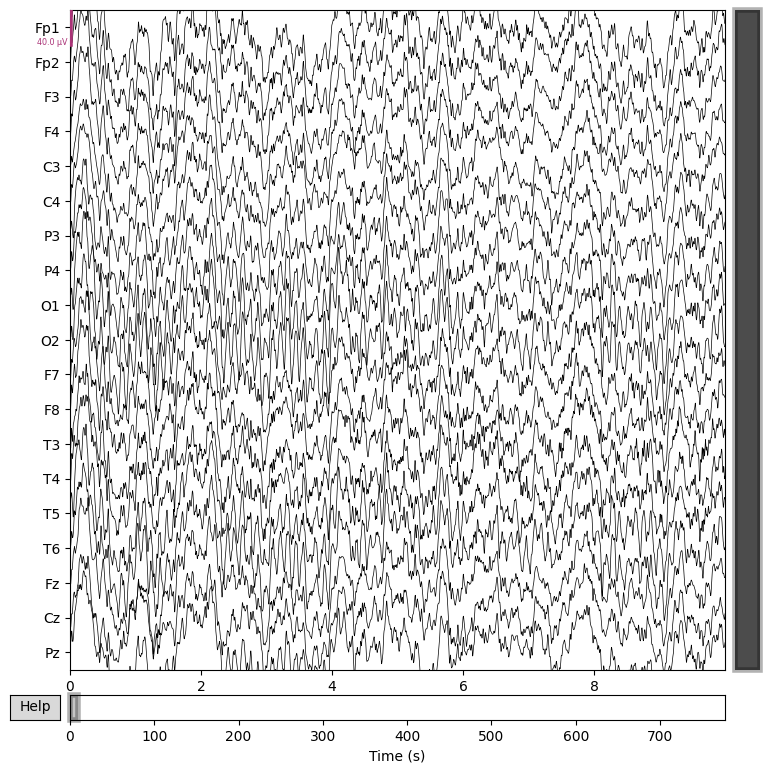

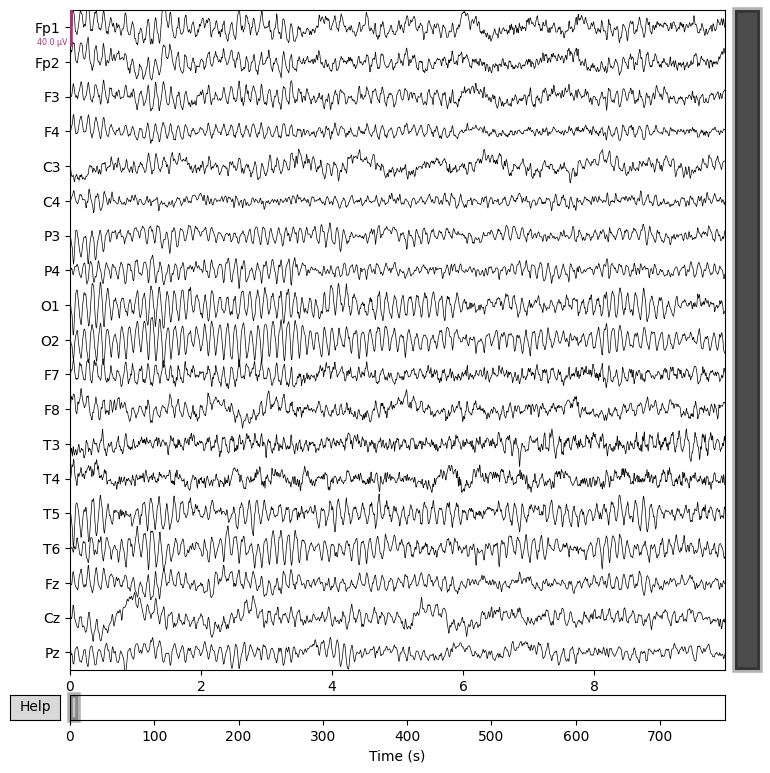

In [12]:
preview_subject = "sub-037"
original_path = input_dir / f"{preview_subject}_task-eyesclosed_eeg.set"
processed_path = output_dir / f"{preview_subject}_task-eyesclosed_eeg_cleaned_raw.fif"

if original_path.exists() and processed_path.exists():
    original_raw = mne.io.read_raw_eeglab(original_path, preload=True)
    processed_raw = mne.io.read_raw_fif(processed_path, preload=True)

    original_raw.plot()
    processed_raw.plot()
else:
    print(f"Preview files for {preview_subject} were not found.")